## Initial Output Analysis: Raw NLDAS and CM
Analysis of model output using raw NLDAS forcings and the CM version of the snow model.

In [1]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
from buildforcing.datasets import PNNLSnotel
import os

In [2]:
# Define environment for paths
path_env = 'desktop' # 'desktop' or 'alpine'

In [3]:
# Configure environment
if path_env == 'desktop':
    output_path = 'C:/Users/clmbn/NMT_PhD/data/output' #desktop
    snotel_path = 'C:/Users/clmbn/NMT_PhD/data/snotel/' #desktop
elif path_env == 'alpine':
    output_path = r'/projects/ccox1@xsede.org/lm4px_modelling/output' #Alpine
    snotel_path = r'/projects/ccox1@xsede.org/data/snotel/'
else:
    raise ValueError("Invalid path_env. Choose 'desktop' or 'alpine'.")

In [4]:
# Run configuration
snotel_site = 'Tony Grove RS'  #Use the Snotel name
spin_up = '100y'
forcings = 's00000000'
run_config = 'v0.1'

In [5]:
# Convert name for output paths
site = snotel_site.replace(' ','').lower()
print(f'Output site: {site}')

Output site: tonygrovers


Load the 'Land Daily' diagnostic from output.

In [6]:
output_folder = os.path.join(output_path,f'{site}/{site}_{forcings}_{run_config}/history/')

In [7]:
# Find the land daily file name in folder and open
land_daily=None
for filename in os.listdir(output_folder):
    if filename.endswith(".land_daily.nc"):
        land_daily = xr.open_dataset(output_folder + filename)
if not land_daily:
    print('Error: no land daily found')

### Notes on timezone:
- Model output is in UTC, but it is a daily average set to noon. This means that a timezone shift to mountain time will not change the date.
- Since there is no change in date from timezone and the data is daily, I won't convert the timezone of the model output.

In [8]:
# Extract snow data from Land Daily dataset
snow_data = land_daily[['snow','snow_depth','snow_density']].isel(grid_index=0).to_dataframe()
snow_data.index = snow_data.index.to_datetimeindex()

# Convert index to America/Denver timezone
# snow_data.index = snow_data.index.tz_localize('UTC').tz_convert('America/Denver')

C:\Users\clmbn\AppData\Local\Temp\ipykernel_11572\4036538477.py:3: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  snow_data.index = snow_data.index.to_datetimeindex()


In [9]:
# Set time of model output to midnight
snow_data.index = snow_data.index - pd.Timedelta(hours=12)

Load the Snotel data

In [10]:
snotel = PNNLSnotel(snotel_site, snotel_path)

In [11]:
snotel_data = snotel.data

In [12]:
# Remove timezone from Snotel data index so it can be compared with model data
snotel_data.index = snotel_data.index.tz_localize(None)

Comparison plots

Text(0.5, 1.0, 'Tony Grove RS nldas cm')

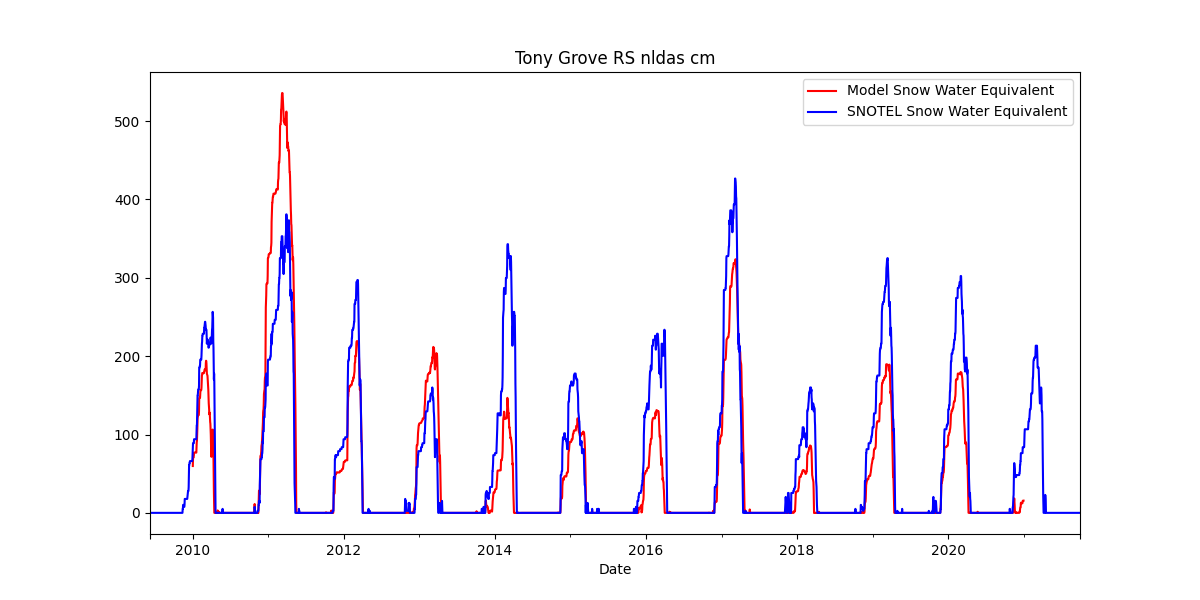

In [13]:
fig, axs = plt.subplots(1, 1, figsize=(12, 6))
snow_data['snow'].plot(ax=axs, label='Model Snow Water Equivalent', color='red')
snotel_data['swe_mm'].plot(ax=axs, label='SNOTEL Snow Water Equivalent', color='blue')
axs.legend()
plt.title(f'{snotel_site} nldas cm')

In [ ]:
plt.savefig('quemazon_test.png')

### Calculate the difference between the model and Snotel data

In [14]:
snow_combined = pd.merge(snotel_data['swe_mm'], snow_data['snow'], how='inner', left_index=True, right_index=True)
snow_combined.columns = ['snotel_swe', 'model_swe']

I am seeing small negative values for SWE model output, not sure what is going on.

In [15]:
# Calculate water year for each date
def water_year(date):
    if date.month < 10:
        return date.year
    else:
        return date.year + 1
    
snow_combined['water_year'] = snow_combined.index.to_series().apply(water_year)


In [16]:
# Calculate model - Snotel difference
snow_combined['swe_diff'] = snow_combined['model_swe'] - snow_combined['snotel_swe']

In [17]:
# Calculate RMSE by water year
rmse_by_wateryear = snow_combined.groupby('water_year')['swe_diff'].apply(
    lambda x: (x ** 2).mean() ** 0.5
)

In [18]:
print(rmse_by_wateryear.tail())

water_year
2017    43.943109
2018    35.060862
2019    46.901288
2020    48.787143
2021    39.101930
Name: swe_diff, dtype: float64


RMSE:
- Tonygrove on the order of 45
- Quemazon has many more datapoints, but RMSE looks similar, more spread?

